# Catalogue Quality Challenge — Exploratory Data Analysis

## Objective and analysis scope

The task is to predict whether a catalogue listing contains a controlled corruption.
`target=0` indicates no controlled corruption and `target=1` indicates one controlled corruption.
Missing values, discounts and legitimate category alternatives may occur in either class.

**This notebook loads only `train.csv`.** All tables, plots, parsing checks and modelling decisions
use the training data. The prediction dataset is reserved for final inference in the training notebook.

The analysis covers data integrity, class balance, missingness, numeric ranges, text quantities,
brand consistency, product aliases and duplicate text. Each section connects the evidence to a
modelling decision. Descriptive associations are distinguished from held-out predictive performance.

Run all cells in order using `requirements-notebook.txt`. Core parsing functions are included here;
this notebook does not require the project's Python package at runtime.

## 1. Training data integrity

Each row represents one offer. IDs must be unique, the target must be binary, and observed prices,
weights and pack sizes must be positive. Seller groups define the unit of validation.

In [1]:
%matplotlib inline
import hashlib
import json
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import GroupKFold

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_colwidth", 95)
TEAL, ORANGE = "#087f8c", "#e68a2e"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/dsc-pjatk-catalogue-quality-challenge/train.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Keep this notebook inside the project containing data/.")
DATA = ROOT / "data/dsc-pjatk-catalogue-quality-challenge"
train = pd.read_csv(DATA / "train.csv")

In [2]:
assert train.id.notna().all() and train.id.is_unique
assert train.seller_id.notna().all()
assert train.target.notna().all() and train.target.isin([0, 1]).all()
numeric = ["price_pln", "shipping_weight_kg", "pack_size"]
for name in numeric:
    observed = train[name].dropna()
    assert np.isfinite(observed).all() and observed.gt(0).all()
assert train.pack_size.dropna().mod(1).eq(0).all()
display(pd.Series({"Training listings": len(train), "Training sellers": train.seller_id.nunique(),
                   "Positive listings": int(train.target.sum()), "Positive fraction": train.target.mean()}).to_frame("value"))
display(train[["title", "description", "declared_category", "pack_size", "target"]].head(3))
display(train.groupby("seller_id").size().describe().to_frame("listings_per_seller"))

,value
Training listings,16000.000000
Training sellers,800.000000
Positive listings,2721.000000
Positive fraction,0.170063


,title,description,declared_category,pack_size,target
0,recording mic support — pack of one — Mira A513,Pack of one main items. Microphone stand by Mira. Variant: standard. For listening at home ...,audio,1.0,1
1,in-ear cable headphones — quantity 2 — Noro E315,Included main items: 2. Wired earbuds by Noro. Variant: compact. For listening at home or a...,computers,2.0,1
2,Tenso digital food balance / standard / quantity 1,Included main items: 1. Kitchen scale by Tenso. Variant: standard. For food preparation or ...,kitchen,1.0,0


,listings_per_seller
count,800.0
mean,20.0
std,0.0
min,20.0
25%,20.0
50%,20.0
75%,20.0
max,20.0


**Implication:** keep all offers from a seller in the same validation fold. Listing and seller IDs
are used for alignment and grouping, and are excluded from predictive features.

## 2. Class balance and missing information

The positive class is a minority. A majority-class accuracy score would hide failures to detect
corrupted offers, so the training notebook evaluates ROC-AUC and Average Precision.
Missing observations are retained as unknowns, with missingness information available to the model.

,listings,fraction
target,,
0,13279,0.8299
1,2721,0.1701


,missing_pct,target0_missing_pct,target1_missing_pct
title,2.94,3.01,2.57
description,4.25,4.35,3.75
declared_category,2.34,2.30,2.50
brand,5.92,6.02,5.40
price_pln,3.89,3.81,4.30
shipping_weight_kg,6.01,5.98,6.17
pack_size,3.03,2.99,3.23


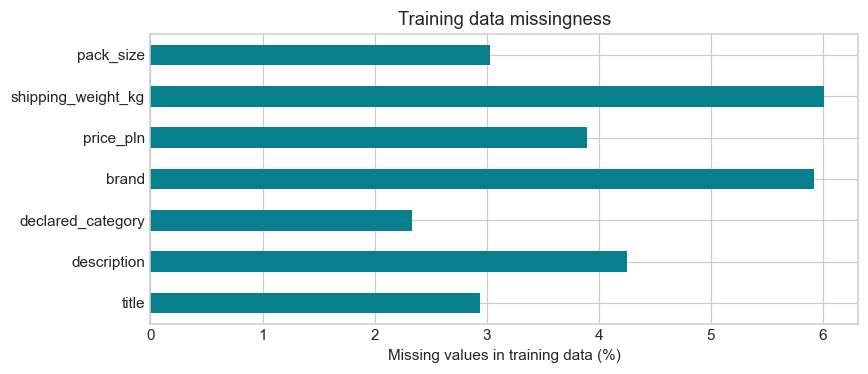

,rows
Both text fields missing,0
Missing descriptions with a title,680


In [3]:
display(train.target.value_counts().sort_index().to_frame("listings").assign(
    fraction=train.target.value_counts(normalize=True).sort_index()).round(4))
fields = train.columns.drop("target")
missing = pd.DataFrame({
    "missing_pct": train[fields].isna().mean() * 100,
    "target0_missing_pct": train.loc[train.target.eq(0), fields].isna().mean() * 100,
    "target1_missing_pct": train.loc[train.target.eq(1), fields].isna().mean() * 100,
})
missing = missing.loc[missing.missing_pct.gt(0)]
display(missing.round(2))
ax = missing.missing_pct.plot.barh(color=TEAL, figsize=(8, 3.5))
ax.set(xlabel="Missing values in training data (%)", ylabel="", title="Training data missingness")
plt.tight_layout(); plt.show()
display(pd.Series({"Both text fields missing": int((train.title.isna() & train.description.isna()).sum()),
                   "Missing descriptions with a title": int((train.description.isna() & train.title.notna()).sum())}).to_frame("rows"))

**Implication:** use the other text field to recover information when possible, and report performance
separately for missing-description rows. A missing value alone does not establish corruption.
Similar missingness between target classes does not establish that values are missing at random.

## 3. Numeric distributions and category composition

Raw price and weight reflect different product types, variants and quantities. Log transformations
make multiplicative differences easier to interpret. Distribution tails motivate contextual checks,
rather than a single global outlier threshold.

,price_pln,shipping_weight_kg,pack_size
count,15377.000,15038.000,15515.000
mean,145.473,0.976,1.519
std,212.007,1.647,0.996
min,0.970,0.024,1.000
1%,8.758,0.077,1.000
50%,77.510,0.459,1.000
99%,1046.447,7.599,5.000
max,3464.270,32.831,5.000


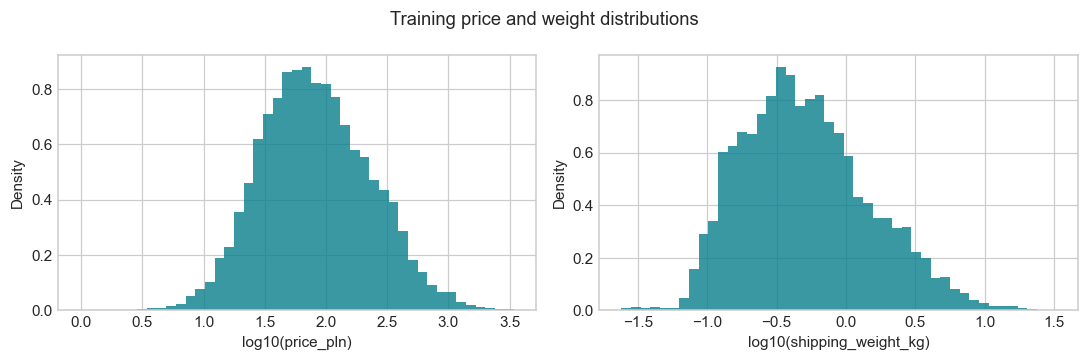

In [4]:
display(train[numeric].describe(percentiles=[.01, .5, .99]).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, name in zip(axes, ["price_pln", "shipping_weight_kg"]):
    values = np.log10(train[name].dropna())
    ax.hist(values, bins=45, density=True, color=TEAL, alpha=.8)
    ax.set(xlabel="log10(" + name + ")", ylabel="Density")
fig.suptitle("Training price and weight distributions")
plt.tight_layout(); plt.show()

In [5]:
category = train.declared_category.fillna("missing")
category_report = train.assign(category=category).groupby("category").target.agg(
    rows="size", positives="sum", positive_fraction="mean").sort_values("positive_fraction")
category_report["training_fraction"] = category.value_counts(normalize=True)
display(category_report.round(4))
display(train.groupby("pack_size", dropna=False).target.agg(rows="size", positive_fraction="mean").round(4))

,rows,positives,positive_fraction,training_fraction
category,,,,
books,1691,229,0.1354,0.1057
sport,1837,257,0.1399,0.1148
audio,2535,380,0.1499,0.1584
beauty,1622,258,0.1591,0.1014
computers,2759,441,0.1598,0.1724
pets,863,149,0.1727,0.0539
kitchen,2253,389,0.1727,0.1408
missing,374,68,0.1818,0.0234
garden,1331,281,0.2111,0.0832


,rows,positive_fraction
pack_size,,
1.0,10986,0.1508
2.0,2499,0.1845
3.0,1283,0.2206
5.0,747,0.3106
NaN,485,0.1814


**Implication:** retain category and pack size and model their relationships with product identity.
Differences in positive rates are descriptive associations, not categorical rules. A variable can
contribute through interactions even when its signed, univariate association is weak.

## 4. Main quantities and free accessories

Main-item quantities appear as digits or number words. An accessory count must not replace the
main count. The phrase `Package contains 2 pcs` is a valid main quantity, while `3 pcs of free
accessory pieces` is a different attribute. The parser recognizes these contexts explicitly.

In [6]:
MISSING = '__missing__'
NUMERIC_COLUMNS = ['price_pln', 'shipping_weight_kg', 'pack_size']
CATEGORICAL_FEATURES = ['declared_category', 'brand', 'condition', 'product', 'variant']
WORDS = {'one': 1, 'two': 2, 'three': 3, 'five': 5}
COUNT = '(\\d+|one|two|three|five)'
DESCRIPTION_PATTERNS = ['included main items:\\s*(\\d+|one|two|three|five)', 'package contains\\s+(\\d+|one|two|three|five)\\s+pcs', 'bundle quantity:\\s*(\\d+|one|two|three|five)\\s+units', 'sold as a\\s+(\\d+|one|two|three|five)-pack', 'pack of\\s+(\\d+|one|two|three|five)\\s+main items', '(\\d+|one|two|three|five)\\s+individually boxed main items']
TITLE_PATTERNS = ['quantity\\s+(\\d+|one|two|three|five)\\b', 'pack of\\s+(\\d+|one|two|three|five)\\b', '\\b(\\d+|one|two|three|five)\\s*(?:-pack|pcs|units|main items)\\b']

def normalize(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(value)).lower()).strip()


def extract_quantity(text, description=False):
    """Only main-item contexts qualify; accessory counts are not a fallback."""
    text = normalize(text)
    for pattern in DESCRIPTION_PATTERNS if description else TITLE_PATTERNS:
        match = re.search(pattern, text)
        if match:
            token = match.group(1)
            value = WORDS[token] if token in WORDS else int(token)
            return float(value) if value > 0 else np.nan
    return np.nan


def parsed_features(df):
    x = df[["declared_category", "brand", "condition", *NUMERIC_COLUMNS]].copy()
    title, desc = df.title.map(normalize), df.description.map(normalize)
    # The fixed grammar is from the supplied synthetic dataset. Unfamiliar
    # grammar stays unknown instead of inventing an identity.
    x["product"] = desc.str.extract(
        r"(?:^|\. )([^.]*) by (?:aster|mira|noro|tenso|velto)\.", expand=False
    )
    x["variant"] = desc.str.extract(r"variant:\s*(\w+)", expand=False).astype("string")
    x["variant"] = x.variant.fillna(
        title.str.extract(r"\b(standard|compact|large)\b", expand=False).astype("string")
    )
    x["desc_quantity"] = desc.map(lambda s: extract_quantity(s, description=True))
    x["title_quantity"] = title.map(extract_quantity)
    x["main_quantity"] = x.desc_quantity.fillna(x.title_quantity)
    x["quantity_difference"] = x.pack_size - x.main_quantity
    x["title_desc_quantity_difference"] = x.title_quantity - x.desc_quantity
    x["clearance"] = desc.str.contains("clearance promotion", regex=False).astype(int)
    x["accessory"] = desc.str.contains("free accessory", regex=False).astype(int)
    x["title_length"], x["description_length"] = title.str.len(), desc.str.len()
    for col in NUMERIC_COLUMNS:
        x[col + "_missing"] = df[col].isna().astype(int)
        x["log_" + col] = np.log(df[col])
    for col in ["price_pln", "shipping_weight_kg"]:
        x[col + "_per_declared_item"] = df[col] / df.pack_size
        x[col + "_per_text_item"] = df[col] / x.main_quantity
    for col in CATEGORICAL_FEATURES:
        x[col] = x[col].fillna(MISSING).astype(str)
    return x.replace([np.inf, -np.inf], np.nan)

In [7]:
examples = ["Also includes 3 pcs of free accessory pieces. Included main items: 1.",
            "Package contains 2 pcs.", "Five individually boxed main items.",
            "Also includes 3 pcs of free accessory pieces."]
display(pd.DataFrame({"description": examples,
                      "main_quantity": [extract_quantity(s, description=True) for s in examples]}))
X = parsed_features(train)
known = X.main_quantity.notna() & train.pack_size.notna()
state = pd.Series("unknown", index=train.index)
state.loc[known & X.quantity_difference.eq(0)] = "agrees"
state.loc[known & X.quantity_difference.ne(0)] = "disagrees"
display(train.assign(quantity_state=state).groupby("quantity_state").target.agg(
    rows="size", positives="sum", positive_fraction="mean").round(4))
display(pd.Series({"Description quantity coverage": X.desc_quantity.notna().mean(),
                   "Combined quantity coverage": X.main_quantity.notna().mean(),
                   "Agreement on observed target-0 pairs": X.loc[known & train.target.eq(0), 'quantity_difference'].eq(0).mean()}).to_frame("fraction").round(5))

,description,main_quantity
0,Also includes 3 pcs of free accessory pieces. Included main items: 1.,1.0
1,Package contains 2 pcs.,2.0
2,Five individually boxed main items.,5.0
3,Also includes 3 pcs of free accessory pieces.,NaN


,rows,positives,positive_fraction
quantity_state,,,
agrees,15115,2241,0.1483
disagrees,391,391,1.0000
unknown,494,89,0.1802


,fraction
Description quantity coverage,0.95750
Combined quantity coverage,0.99938
Agreement on observed target-0 pairs,1.00000


All observed quantity disagreements found by this parser are positive in the training data. This
is descriptive evidence rather than a guarantee for future listings. Unknown quantities are kept
separate because comparing `NaN != pack_size` would incorrectly count them as disagreements.

## 5. Brand consistency

Descriptions contain a `product by brand` phrase. Agreement is evaluated only when both the
extracted brand and structured brand are present; recoverable missing brands are counted separately.

In [8]:
description_brand = train.description.map(normalize).str.extract(
    r"\bby\s+(aster|mira|noro|tenso|velto)\b", expand=False)
both = description_brand.notna() & train.brand.notna()
display(pd.Series({"Observed text/column brand pairs": int(both.sum()),
                   "Agreement among observed pairs": description_brand[both].eq(train.brand[both].str.lower()).mean(),
                   "Missing structured brands available in description": int((train.brand.isna() & description_brand.notna()).sum())}).to_frame("value"))

,value
Observed text/column brand pairs,14406.0
Agreement among observed pairs,1.0
Missing structured brands available in description,914.0


**Implication:** text provides redundant catalogue information. Agreement alone does not establish
predictive value; the final feature set focuses on product identity and cross-field consistency.

## 6. Product identity and title aliases

Titles and descriptions often name the same product differently, such as `recording mic support`
and `microphone stand`. Paired training text can teach a title-to-description alias dictionary.
It fills missing product identities while preserving identities parsed directly from descriptions.

Cleaning removes model codes and quantity phrases while preserving product words. Ambiguous or
unseen aliases remain unknown. The dictionary uses no labels and is fitted inside each training split.

In [9]:
BRANDS = 'aster|mira|noro|tenso|velto'
NUMBER = '(?:\\d+|one|two|three|four|five|six|seven|eight|nine|ten)'

def title_product_key(title):
    text = normalize(title)
    text = re.sub(r"\([^)]*\)", " ", text)
    text = re.sub(rf"\b({BRANDS})(?=[a-z]\d+\b)", r"\1 ", text)
    text = re.sub(r"\b[a-z]\d+\b", " ", text)
    text = re.sub(rf"\b(?:{BRANDS})\b", " ", text)
    text = re.sub(r"\b(?:standard|compact|large)\b", " ", text)
    text = re.sub(rf"\b(?:quantity|pack of|set of)\s+{NUMBER}\b", " ", text)
    text = re.sub(rf"\b{NUMBER}\s*(?:-?pack|pcs|units|main items)\b", " ", text)
    text = re.sub(r"[^a-z0-9 ]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def fit_title_aliases(raw):
    pairs = pd.DataFrame({"key": raw.title.map(title_product_key),
                          "product": parsed_features(raw)['product']})
    pairs = pairs.loc[pairs.key.ne("") & pairs['product'].ne(MISSING)]
    # Conflicting mappings stay unknown rather than resolving by arbitrary order.
    counts = pairs.groupby("key")['product'].nunique()
    unambiguous = counts.index[counts.eq(1)]
    return pairs.loc[pairs.key.isin(unambiguous)].drop_duplicates("key").set_index("key")['product'].to_dict()


def apply_title_aliases(raw, features, aliases):
    x = features.copy()
    inferred = raw.title.map(title_product_key).map(aliases)
    missing = x['product'].eq(MISSING)
    x.loc[missing, 'product'] = inferred.loc[missing].fillna(MISSING)
    return x

In [10]:
paired = pd.DataFrame({"title_key": train.title.map(title_product_key), "description_product": X['product']})
paired = paired.loc[paired.title_key.ne("") & paired.description_product.ne(MISSING)]
display(paired.drop_duplicates().head(10))
alias_counts = paired.groupby("title_key").description_product.nunique()
display(pd.Series({"Distinct description phrases": X.loc[X['product'].ne(MISSING), 'product'].nunique(),
                   "Title keys seen with descriptions": len(alias_counts),
                   "Ambiguous title keys": int(alias_counts.gt(1).sum())}).to_frame("count"))

,title_key,description_product
0,recording mic support,microphone stand
1,in ear cable headphones,wired earbuds
2,digital food balance,kitchen scale
3,litter scoop velo,cat tray cleaning shovel
4,laptop sleeve,notebook protective pouch
5,portable wireless loudspeaker,bluetooth speaker
6,outdoor sports ball,football
7,electric kettle,countertop water boiler
8,stick food mixer,hand blender
9,home cooking guide,recipe book


,count
Distinct description phrases,180
Title keys seen with descriptions,1134
Ambiguous title keys,0


Recovery coverage is measured on sellers excluded from dictionary fitting. These are held-out
subsets of the training data. The following check measures coverage, not classifier performance.

In [11]:
fold_id = np.array([int(hashlib.sha256(f"42:{s}".encode()).hexdigest()[:16], 16) % 5
                    for s in train.seller_id])
recovered = pd.Series(MISSING, index=train.index)
for fold in range(5):
    fit, held_out = train.loc[fold_id != fold], train.loc[fold_id == fold]
    aliases = fit_title_aliases(fit)
    recovered.loc[held_out.index] = apply_title_aliases(held_out, parsed_features(held_out), aliases)['product']
missing_description = train.description.isna()
recovered_count = int((missing_description & recovered.ne(MISSING)).sum())
display(pd.DataFrame({"missing_descriptions": [int(missing_description.sum())],
                      "product_recovered_on_held_out_sellers": [recovered_count],
                      "still_unknown": [int(missing_description.sum()) - recovered_count]}))
display(train.loc[missing_description, ['title']].assign(recovered_product=recovered[missing_description]).head(8))

,missing_descriptions,product_recovered_on_held_out_sellers,still_unknown
0,680,639,41


,title,recovered_product
16,seedling starter container — 2 pcs — Mira D215,seed tray
31,MIRA USB VIDEO WEBCAM / LARGE / 1 PCS,web camera
36,Tenso A986: standard USB microphone (quantity 3),desktop recording mic
52,TENSO E881: STANDARD DIGITAL DRAWING PAD (QUANTITY 2),graphics tablet
88,Aster B949: standard printed piano score collection (1 units),sheet music book
120,Aster weatherproof garden container / standard / 1 pcs,outdoor storage box
151,Tenso C468: standard plant growing guide (one main items),gardening handbook
175,Aster C356: standard stick food mixer (1 pcs),hand blender


**Implication:** use title aliases to recover product identity and evaluate coverage separately from
predictive quality. During classifier training, both outer and inner seller splits must fit their
own dictionaries. Unknown aliases need conservative handling.

## 7. Repeated text and unique offers

Templated text can repeat for different offers. Missing text is excluded from single-field duplicate
counts, and repeated complete text pairs are checked for label consistency.

In [12]:
repeated = []
for column in ["title", "description"]:
    values = train[column].dropna().map(normalize)
    repeated.append({"field": column, "rows_in_repeated_text_groups": int(values.duplicated(keep=False).sum())})
complete = train.loc[train.title.notna() & train.description.notna()].copy()
groups = complete.assign(title_key=complete.title.map(normalize), description_key=complete.description.map(normalize))
pairs = groups.groupby(["title_key", "description_key"]).target.agg(rows="size", labels="nunique")
display(pd.DataFrame(repeated))
display(pd.Series({"Repeated complete text-pair groups": int(pairs.rows.gt(1).sum()),
                   "Repeated pairs with mixed targets": int((pairs.rows.gt(1) & pairs.labels.gt(1)).sum())}).to_frame("count"))

,field,rows_in_repeated_text_groups
0,title,1083
1,description,620


,count
Repeated complete text-pair groups,22
Repeated pairs with mixed targets,6


## 8. Findings and modelling decisions

| Training-data finding | Modelling decision |
|---|---|
| Multiple offers per seller | Keep sellers together in validation |
| Minority positive class | Evaluate ROC-AUC and Average Precision |
| Missing attributes and redundant text | Preserve unknowns; recover product identity from paired text |
| Main quantities and accessories share numbers | Parse quantity by context and retain an unknown group |
| Categories and products have contextual relationships | Learn smoothed category compatibility |
| Price and weight vary by product, quantity and variant | Use contextual regressions and robust product references |
| Repeated text can have different labels | Avoid text-to-target lookup rules |

These findings support the method implemented in `02_training_pipeline.ipynb`. That notebook fits
learned features inside seller splits, evaluates held-out training rows, and loads the prediction
dataset only for final inference after the model and validation stages are complete.